<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/Ex8_Normal_Abnormal_physiolog_signals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 8: Classification of Normal and Abnormal Physiological Signals

**Aim:** Implement classification models to distinguish between normal and abnormal physiological (ECG heartbeat) signals using extracted signal features and perform comparative analysis of different ML models.

**Dataset:** Kaggle ECG Heartbeat Categorization Dataset — PTB Diagnostic ECG Database (`ptbdb_normal.csv`, `ptbdb_abnormal.csv`).

**Models compared:** Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, Support Vector Machine.

**Evaluation:** Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices and comparison graph.

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Dataset
Download `ptbdb_normal.csv` and `ptbdb_abnormal.csv` from the Kaggle dataset and place them in the same folder as this notebook. Each row contains ECG signal samples; the final column is the class label.

In [2]:
normal = pd.read_csv('ptbdb_normal.csv', header=None)
abnormal = pd.read_csv('ptbdb_abnormal.csv', header=None)

print('Normal shape  :', normal.shape)
print('Abnormal shape:', abnormal.shape)
normal.head()

Normal shape  : (4046, 188)
Abnormal shape: (10506, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Combine both classes
data = pd.concat([normal, abnormal], ignore_index=True)
X = data.iloc[:, :-1].copy()
y = data.iloc[:, -1].astype(int).copy()

print('Combined shape:', data.shape)
print('Features:', X.shape[1])
print('Class distribution:')
print(y.value_counts().sort_index().rename(index={0:'Normal', 1:'Abnormal'}))

Combined shape: (14552, 188)
Features: 187
Class distribution:
187
Normal       4046
Abnormal    10506
Name: count, dtype: int64


Missing values: 0
Duplicate rows : 7


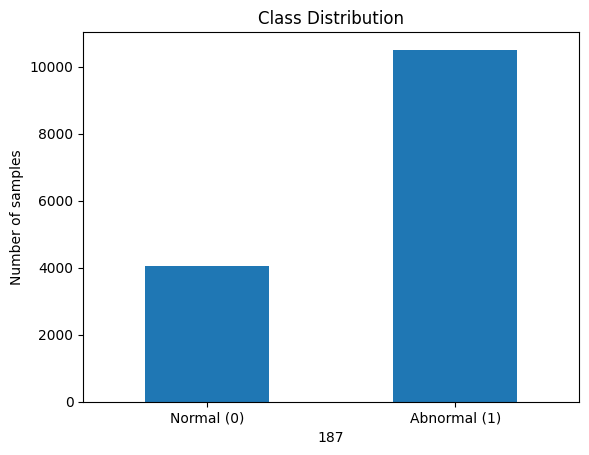

In [4]:
# Basic data-quality checks
print('Missing values:', X.isnull().sum().sum())
print('Duplicate rows :', data.duplicated().sum())

# Class distribution plot
y.value_counts().sort_index().plot(kind='bar')
plt.xticks([0,1], ['Normal (0)', 'Abnormal (1)'], rotation=0)
plt.ylabel('Number of samples')
plt.title('Class Distribution')
plt.show()

## 2. Train-Test Split and Preprocessing
A stratified split preserves the normal/abnormal proportion. Scaling is included in models that are sensitive to feature magnitude.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 11641
Testing samples : 2911


In [6]:
# Define different ML models
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE))
    ])
}
print('Models:', list(models.keys()))

Models: ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']


## 3. Train Models and Perform Comparative Analysis

In [7]:
results = []
predictions = {}

for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score)
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df.round(4)

Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training SVM...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9701,0.9688,0.9905,0.9795,0.9940
1,KNN,0.9200,0.9521,0.9363,0.9441,0.9663
2,Decision Tree,0.8839,0.9546,0.8811,0.9164,0.9009
3,SVM,0.8815,0.9641,0.8682,0.9136,0.9578
4,Logistic Regression,0.7867,0.9049,0.7873,0.8420,0.8712


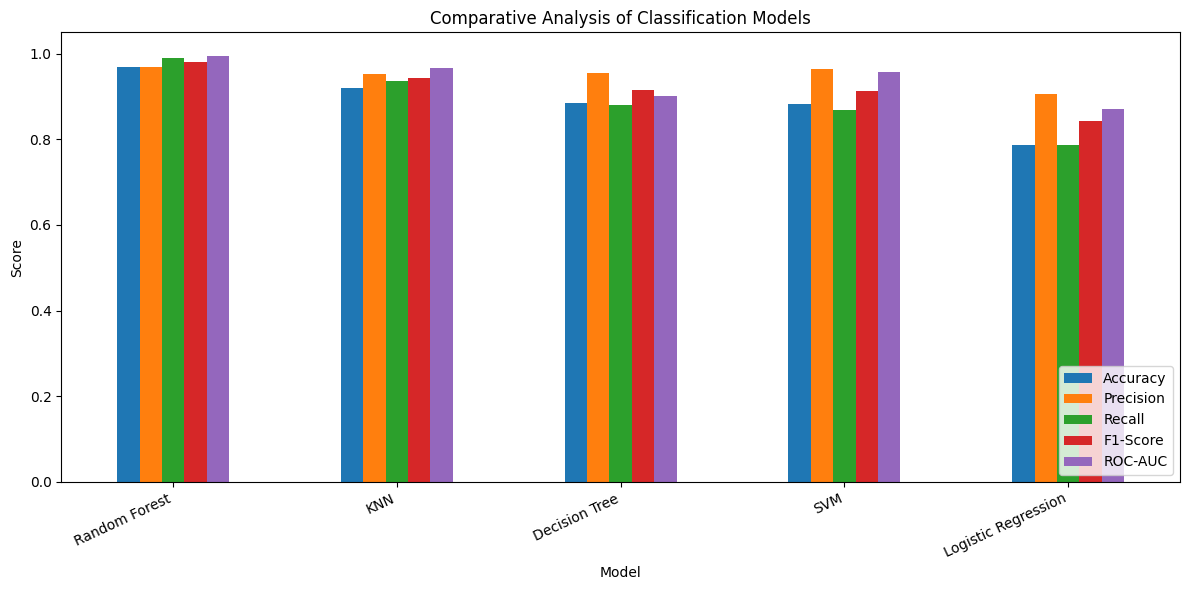

In [8]:
# Comparison graph
plot_df = results_df.set_index('Model')[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']]
ax = plot_df.plot(kind='bar', figsize=(12,6))
plt.ylim(0, 1.05)
plt.ylabel('Score')
plt.title('Comparative Analysis of Classification Models')
plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# Confusion matrices for all models
for name, y_pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=['Normal','Abnormal'], cmap='Blues'
    )
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [9]:
# Detailed report of the best model
best_model_name = results_df.iloc[0]['Model']
print('Best model based on F1-Score:', best_model_name)
print(classification_report(y_test, predictions[best_model_name],
                            target_names=['Normal','Abnormal']))

Best model based on F1-Score: Random Forest
              precision    recall  f1-score   support

      Normal       0.97      0.92      0.94       809
    Abnormal       0.97      0.99      0.98      2102

    accuracy                           0.97      2911
   macro avg       0.97      0.95      0.96      2911
weighted avg       0.97      0.97      0.97      2911



## 4. Result and Conclusion
The notebook trains five classification algorithms on ECG heartbeat samples and compares them using the same test set. The final table and graph allow the best model to be selected objectively using Accuracy, Precision, Recall, F1-score and ROC-AUC. For medical classification, Recall and F1-score are particularly useful because missing abnormal cases can be important.

**Result:** Run all cells and report the model ranked first in the comparison table as the best-performing model for this split.